# Piloto FinBERT v3: Comparativa Empírica Completa (Regex Unificada vs. spaCy)

Este notebook mide **en vivo y en igualdad de condiciones** (misma máquina, misma muestra de 600 artículos, mismo `batch_size=8` y mismo `max_len=512`) todos los enfoques de extracción para FinBERT, **sin ningún dato hardcodeado**:

| Enfoque | Segmentador | Poda Boilerplate | Normalización + `[SEP]` | Ventana |
| :--- | :--- | :---: | :---: | :---: |
| **`TRUNC_512`** | Corte ciego 512 | No | No | N/A |
| **`REGEX_OLD_V1`** | Regex antigua (sin abreviaturas) | No | No | ±1 |
| **`RE_V1_PODA`** | Regex mejorada (`base_nlp.py`) | Sí | Sí | ±1 |
| **`RE_V0_PODA`** | Regex mejorada (`base_nlp.py`) | Sí | Sí | **0** |
| **`SPACY_S1B`** | spaCy (`en_core_web_sm` `Doc.sents`) | Sí | Sí | ±1 |
| **`SPACY_S0`** | spaCy (`en_core_web_sm` `Doc.sents`) | Sí | Sí | **0** |

In [1]:
# 0. Dependencias (instala spaCy + en_core_web_sm solo si faltan para la comparativa empírica)
import importlib.util, subprocess
if importlib.util.find_spec("spacy") is None:
    subprocess.check_call(["uv", "pip", "install", "spacy"])
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.check_call(["uv", "pip", "install", "en_core_web_sm@https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl"])
print("[OK] spaCy listo para benchmark empírico")

[OK] spaCy listo para benchmark empírico


In [2]:
# 0.1. Configuración del entorno, spaCy y FinBERT
import re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

curr = Path.cwd()
PROJ_ROOT = next((p for p in [curr, curr.parent, curr.parent.parent] if (p / "pyproject.toml").exists()), curr)
for p in (PROJ_ROOT / "src", PROJ_ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from dependencies.dependencies import get_storage_repository, get_compactor
from articulos.models.base_nlp import BaseProcesadorArticulo
from shared.tickets import ALIAS_BANCOS, BOILERPLATE_SECTOR_PATTERNS

nlp = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")
finbert = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert").eval()
LBL = {v.lower(): k for k, v in finbert.config.id2label.items()}
I_POS, I_NEG, I_NEU = LBL["positive"], LBL["negative"], LBL["neutral"]
print(f"[OK] PROJ_ROOT: {PROJ_ROOT} | etiquetas: {finbert.config.id2label}")

c:\proyectos\TFM-Master\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 396.77it/s]

[OK] PROJ_ROOT: c:\proyectos\TFM-Master | etiquetas: {0: 'positive', 1: 'negative', 2: 'neutral'}


## 1. Carga de la Muestra de Control desde Silver (600 artículos largos > 1.500 caracteres)

In [3]:
async def descargar_muestra(key="processed/huggingface/multisource_bancos_2010_2023.parquet", n=600):
    repo, compact = get_storage_repository(), get_compactor()
    try:
        df = pd.DataFrame(compact.decompact(await repo.get(key)))
    finally:
        await repo.close()
    if "is_ruido" in df.columns:
        df = df[~df["is_ruido"]]
    df = df[df["article"].fillna("").str.len() > 1500]
    return df.sample(n=min(n, len(df)), random_state=42).reset_index(drop=True)

df_silver = await descargar_muestra()
print(f"[OK] {len(df_silver)} artículos largos listos (random_state=42).")

 INFO     | 2026-11-19 11:58:51.210622 | S3 Storage Repository | Abriendo canal persistente con el almacenamiento de objetos S3 (Bootstrap Phase)...
 INFO     | 2026-11-19 11:58:51.681896 | S3 Storage Repository | Conectado a S3 con éxito. Bucket por defecto: [tfm-master-prediccion-bancos-usa] | Endpoint: https://ab02a9e85571f8564208e420a50be80a.eu.r2.cloudflarestorage.com/
 INFO     | 2026-11-19 11:58:58.831799 | ParquetCompactor | Descompactados 89,846 registros desde buffer Parquet (43,116,608 bytes).
 INFO     | 2026-11-19 11:59:00.084474 | S3 Storage Repository | Canales del pool de almacenamiento S3 cerrados de forma limpia.
[OK] 600 artículos largos listos (random_state=42).


## 2. Definición de Todos los Enfoques (Regex antigua, Regex unificada y spaCy)

In [4]:
REGEX_OLD = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(])")

def extraer_regex_antigua(titular, cuerpo, ticker, ventana=1):
    cuerpo = (cuerpo or "").strip()
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.strip() for s in REGEX_OLD.split(cuerpo) if s.strip()]
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    pat = re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s)]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()}. " + " ".join(oraciones[i] for i in idx), True

def podar_boilerplate_v2(cuerpo):
    out = cuerpo
    for bp in BOILERPLATE_SECTOR_PATTERNS:
        out = re.sub(bp + r".*?(\n|$)", "", out, flags=re.IGNORECASE)
    out = re.sub(r"^.*Free Stock Analysis Report.*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    out = re.sub(r"^.*(Zacks Investment Research|To read this article on Zacks).*$", "", out, flags=re.IGNORECASE | re.MULTILINE)
    return out

def extraer_spacy_v2(titular, cuerpo, ticker, ventana=1):
    cuerpo = podar_boilerplate_v2((cuerpo or "").strip())
    if not cuerpo:
        return titular.strip(), False
    oraciones = [s.text.strip() for s in nlp(cuerpo).sents if s.text.strip()]
    aliases = ALIAS_BANCOS.get(ticker, [ticker.lower()])
    pat = re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)
    hits = [i for i, s in enumerate(oraciones) if pat.search(s) or pat.search(BaseProcesadorArticulo._normalizar_texto(s))]
    if not hits:
        return f"{titular.strip()}. {oraciones[0] if oraciones else ''}".strip(), False
    idx = sorted({j for i in hits for j in range(i - ventana, i + ventana + 1) if 0 <= j < len(oraciones)})
    return f"{titular.strip()} [SEP] " + " ".join(oraciones[i] for i in idx), True

VARIANTES = {
    "TRUNC_512":     lambda t, c, k: (f"{t.strip()}. {c.strip()}", True),
    "REGEX_OLD_V1":  lambda t, c, k: extraer_regex_antigua(t, c, k, ventana=1),
    "RE_V1_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=1),
    "RE_V0_PODA":    lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0),
    "SPACY_S1B":     lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=1),
    "SPACY_S0":      lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=0),
}

# Prueba rápida de calidad de corte en abreviaturas
demo = "J.P. Morgan Chase & Co. reported profit of $3.5 billion. The U.S. lender beat estimates. Wells Fargo WFC.N. It rose 2%."
print("Regex antigua :", REGEX_OLD.split(demo))
print("Regex mejorada:", BaseProcesadorArticulo.extraer_contexto_banco("Headline", demo, "JPM", ventana_frases=0)[0])
print("spaCy         :", extraer_spacy_v2("Headline", demo, "JPM", ventana=0)[0])

Regex antigua : ['J.P.', 'Morgan Chase & Co. reported profit of $3.5 billion.', 'The U.S. lender beat estimates.', 'Wells Fargo WFC.N.', 'It rose 2%.']
Regex mejorada: Headline [SEP] J.P. Morgan Chase & Co. reported profit of $3.5 billion.
spaCy         : Headline [SEP] J.P. Morgan Chase & Co. reported profit of $3.5 billion.


## 3. Extracción, Inferencia Real con FinBERT y Tabla Comparativa Empírica

In [5]:
@torch.inference_mode()
def puntuar_lote(textos, batch_size=8, max_len=512):
    orden = np.argsort([len(t) for t in textos])
    probs = np.zeros((len(textos), 3), dtype=np.float32)
    for i in range(0, len(textos), batch_size):
        ids = orden[i:i + batch_size]
        enc = tokenizer([textos[j] for j in ids], return_tensors="pt", truncation=True, max_length=max_len, padding=True)
        probs[ids] = torch.softmax(finbert(**enc).logits, dim=-1).numpy()
    return pd.DataFrame({"pos": probs[:, I_POS], "neg": probs[:, I_NEG], "neu": probs[:, I_NEU]}).assign(
        sentiment=lambda d: d.pos - d.neg,
        confidence=lambda d: 1 - d.neu,
    )

@torch.inference_mode()
def puntuar_unitario(textos, max_len=256):
    rows = []
    for t in textos:
        enc = tokenizer(t, return_tensors="pt", truncation=True, max_length=max_len)
        p = torch.softmax(finbert(**enc).logits, dim=-1)[0].numpy()
        rows.append((p[I_POS], p[I_NEG], p[I_NEU]))
    return pd.DataFrame(rows, columns=["pos", "neg", "neu"]).assign(
        sentiment=lambda d: d.pos - d.neg,
        confidence=lambda d: 1 - d.neu,
    )

extr, tiempos_extr = {}, {}
for nombre, fn in VARIANTES.items():
    t0 = time.perf_counter()
    extr[nombre] = [fn(r.title, r.article, r.ticker) for r in df_silver.itertuples()]
    tiempos_extr[nombre] = (time.perf_counter() - t0) * 1000 / len(df_silver)

res, filas_resumen = {}, []
for nombre, lista in extr.items():
    textos = [t for t, _ in lista]
    locs = [l for _, l in lista]
    tok_lens = [len(tokenizer.encode(t, truncation=False)) for t in textos]

    t0 = time.perf_counter()
    df_s = puntuar_lote(textos, batch_size=8, max_len=512)
    dt = time.perf_counter() - t0
    df_s["localizado"] = locs
    res[nombre] = df_s

    filas_resumen.append({
        "Variante": nombre,
        "Extracción (ms/doc)": round(tiempos_extr[nombre], 3),
        "Tokens medios": round(float(np.mean(tok_lens)), 1),
        "% <= 256 tok": round(100 * float(np.mean([x <= 256 for x in tok_lens])), 1),
        "% Localizado": round(100 * float(df_s["localizado"].mean()), 2),
        "Convicción (1-P_neu)": round(float(df_s["confidence"].mean()), 3),
        "|Sentiment| medio": round(float(df_s["sentiment"].abs().mean()), 3),
        "% Neutro (<0.2)": round(100 * float((df_s["confidence"] < 0.2).mean()), 2),
        "FinBERT CPU b=8 (ms/doc)": round(dt * 1000 / len(textos), 1),
    })

df_resumen = pd.DataFrame(filas_resumen)
display(df_resumen)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1726 > 512). Running this sequence through the model will result in indexing errors


,Variante,Extracción (ms/doc),Tokens medios,% <= 256 tok,% Localizado,Convicción (1-P_neu),|Sentiment| medio,% Neutro (<0.2),FinBERT CPU b=8 (ms/doc)
0,TRUNC_512,0.109,941.9,0.0,100.00,0.729,0.593,15.17,904.9
1,REGEX_OLD_V1,0.623,269.9,63.7,99.83,0.604,0.485,27.50,515.7
2,RE_V1_PODA,2.013,252.6,66.2,99.17,0.690,0.563,19.67,560.4
3,RE_V0_PODA,1.885,138.5,86.3,99.17,0.703,0.588,19.50,359.9
4,SPACY_S1B,115.887,237.2,69.0,99.17,0.696,0.571,19.33,589.3
5,SPACY_S0,83.351,125.1,88.8,99.17,0.703,0.590,19.00,255.9


## 4. Acuerdo de Signos y Correlación (Regex Unificada vs. spaCy)

In [6]:
def signo(s, umbral=0.15):
    return np.where(s > umbral, 1, np.where(s < -umbral, -1, 0))

pares = [
    ("RE_V1_PODA", "SPACY_S1B"),
    ("RE_V0_PODA", "SPACY_S0"),
    ("REGEX_OLD_V1", "RE_V1_PODA"),
    ("RE_V1_PODA", "RE_V0_PODA"),
    ("RE_V0_PODA", "TRUNC_512"),
]
filas_acuerdo = []
for a, b in pares:
    sa, sb = signo(res[a]["sentiment"]), signo(res[b]["sentiment"])
    filas_acuerdo.append({
        "Comparativa": f"{a} vs {b}",
        "% Mismo Signo": round(100 * float((sa == sb).mean()), 2),
        "% Inversión (pos<->neg)": round(100 * float((sa * sb == -1).mean()), 2),
        "Corr. Pearson": round(float(np.corrcoef(res[a]["sentiment"], res[b]["sentiment"])[0, 1]), 3),
    })

display(pd.DataFrame(filas_acuerdo))

,Comparativa,% Mismo Signo,% Inversión (pos<->neg),Corr. Pearson
0,RE_V1_PODA vs SPACY_S1B,94.67,1.67,0.955
1,RE_V0_PODA vs SPACY_S0,96.17,0.83,0.965
2,REGEX_OLD_V1 vs RE_V1_PODA,86.33,1.00,0.920
3,RE_V1_PODA vs RE_V0_PODA,72.00,10.17,0.695
4,RE_V0_PODA vs TRUNC_512,60.00,16.17,0.504


## 5. Benchmark Real de Velocidad en CPU (`max_length=256` vs `512` | Unitario vs `Batch=8`)

In [7]:
muestra_64 = [t for t, _ in extr["RE_V0_PODA"][:64]]
bench_rows = []
for max_len in (256, 512):
    t0 = time.perf_counter()
    _ = puntuar_unitario(muestra_64, max_len=max_len)
    ms_u = (time.perf_counter() - t0) * 1000 / 64

    t0 = time.perf_counter()
    _ = puntuar_lote(muestra_64, batch_size=8, max_len=max_len)
    ms_b8 = (time.perf_counter() - t0) * 1000 / 64

    bench_rows.append({"Modo": f"Unitario (max_len={max_len})", "ms/doc": round(ms_u, 1), "Horas (27.217 docs)": round(ms_u * 27217 / 3600000, 2)})
    bench_rows.append({"Modo": f"Batch=8 (max_len={max_len})",  "ms/doc": round(ms_b8, 1), "Horas (27.217 docs)": round(ms_b8 * 27217 / 3600000, 2)})

display(pd.DataFrame(bench_rows))

,Modo,ms/doc,Horas (27.217 docs)
0,Unitario (max_len=256),329.0,2.49
1,Batch=8 (max_len=256),255.0,1.93
2,Unitario (max_len=512),419.3,3.17
3,Batch=8 (max_len=512),314.6,2.38


## 6. Test Multi-Ticker (`RE_V0_PODA` vs `SPACY_S0` en 60 artículos multi-banco)

In [8]:
def _pat_alias(tk):
    aliases = ALIAS_BANCOS.get(tk, [tk.lower()])
    return re.compile(r"\b(" + "|".join(re.escape(a) for a in aliases) + r")\b", re.IGNORECASE)

def bancos_en(texto):
    norm = BaseProcesadorArticulo._normalizar_texto(texto)
    return [k for k in ALIAS_BANCOS if _pat_alias(k).search(texto) or _pat_alias(k).search(norm)]

multi = df_silver[df_silver.apply(lambda r: len(bancos_en(f"{r.title} {r.article}")) >= 2, axis=1)].head(60)
for nombre_mt, fn_mt in [("RE_V0_PODA", lambda t, c, k: BaseProcesadorArticulo.extraer_contexto_banco(t, c, k, ventana_frases=0)),
                         ("SPACY_S0",   lambda t, c, k: extraer_spacy_v2(t, c, k, ventana=0))]:
    filas_mt = []
    for r in multi.itertuples():
        for k in bancos_en(f"{r.title} {r.article}"):
            txt, _ = fn_mt(r.title, r.article, k)
            filas_mt.append({"articulo": r.Index, "banco": k, "texto": txt})
    df_mt = pd.DataFrame(filas_mt)
    df_mt = df_mt.join(puntuar_lote(df_mt["texto"].tolist(), batch_size=8, max_len=256)[["sentiment", "confidence"]])
    disp = df_mt.groupby("articulo")["sentiment"].agg(["count", "std", lambda s: s.max() - s.min()]).rename(columns={"<lambda_0>": "rango"})
    print(f"[{nombre_mt}] Artículos: {len(disp)} | Rango medio: {disp['rango'].mean():.3f} | % rango > 0.3: {100*(disp['rango']>0.3).mean():.1f}%")

[RE_V0_PODA] Artículos: 60 | Rango medio: 0.410 | % rango > 0.3: 35.0%
[SPACY_S0] Artículos: 60 | Rango medio: 0.426 | % rango > 0.3: 36.7%


## 7. Visualización Comparativa Medida en Vivo

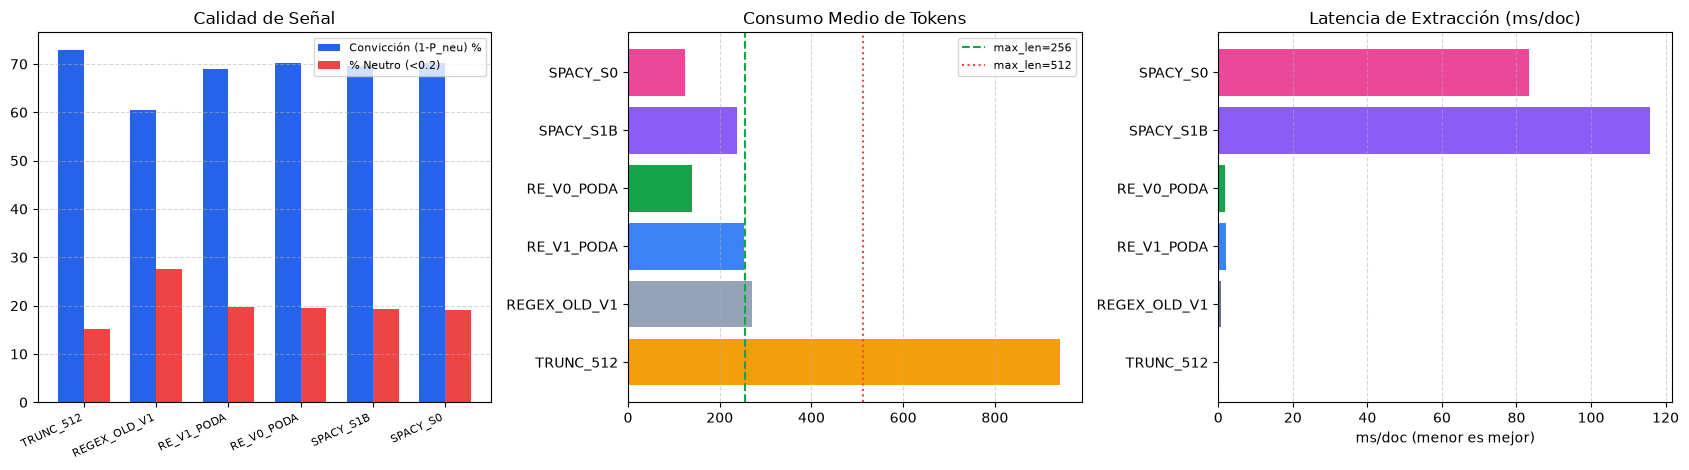

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
df_plot = df_resumen.copy()

x = np.arange(len(df_plot))
w = 0.36
axes[0].bar(x - w/2, df_plot["Convicción (1-P_neu)"] * 100, w, label="Convicción (1-P_neu) %", color="#2563eb")
axes[0].bar(x + w/2, df_plot["% Neutro (<0.2)"], w, label="% Neutro (<0.2)", color="#ef4444")
axes[0].set_title("Calidad de Señal")
axes[0].set_xticks(x)
axes[0].set_xticklabels(df_plot["Variante"], rotation=25, ha="right", fontsize=8)
axes[0].legend(fontsize=8)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].barh(df_plot["Variante"], df_plot["Tokens medios"], color=["#f59e0b", "#94a3b8", "#3b82f6", "#16a34a", "#8b5cf6", "#ec4899"])
axes[1].axvline(256, color="#16a34a", linestyle="--", label="max_len=256")
axes[1].axvline(512, color="#ef4444", linestyle=":", label="max_len=512")
axes[1].set_title("Consumo Medio de Tokens")
axes[1].legend(fontsize=8)
axes[1].grid(axis="x", linestyle="--", alpha=0.5)

axes[2].barh(df_plot["Variante"], df_plot["Extracción (ms/doc)"], color=["#cbd5e1", "#64748b", "#3b82f6", "#16a34a", "#8b5cf6", "#ec4899"])
axes[2].set_title("Latencia de Extracción (ms/doc)")
axes[2].set_xlabel("ms/doc (menor es mejor)")
axes[2].grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()